# Milestone 5 · Model evaluation and analysis of results
**Group 9 · Noise-robust speech recognition with word-level error flagging**

This notebook runs the **complete Milestone 5 evaluation** and shows every table, chart and audio example.
It calls the same functions as the command-line script, so both give identical tables:

```bash
python scripts/m5_evaluate.py            # same evaluation, no notebook
```

The shared code is in `src/group9_ds_ai_lab/evaluation/m5.py`. Nothing is retrained.

| Setting | Meaning |
|---|---|
| `SOURCE = "local"` | load the trained models from the server (`experiments/runs/*/best`) |
| `SOURCE = "hf"` | download the same models from Hugging Face (section 9 shows they are identical) |
| `RECOMPUTE = "none"` | use the saved test-grid outputs (about 2 minutes on CPU) |
| `RECOMPUTE = "greedy"` | re-decode the full test grid on the GPU for every model (about 4 minutes per model) |
| `RUN_GPU = True` | also run the speed benchmark (CPU and GPU) and the Hugging Face check |

The novelty (interview glossary) is **not** part of this notebook.

In [1]:
import os, sys, json, warnings
from pathlib import Path
cwd = Path.cwd()
REPO = next(p for p in (cwd, *cwd.parents) if (p / "src" / "group9_ds_ai_lab").is_dir())
sys.path.insert(0, str(REPO / "src"))
from group9_ds_ai_lab.utils.paths import setup_env
setup_env()
import numpy as np, pandas as pd
from IPython.display import display, Markdown, Image, Audio, HTML
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 120)

from group9_ds_ai_lab.evaluation import m5, models as M

SOURCE = os.environ.get("M5_SOURCE", "local")       # "local" or "hf"
RECOMPUTE = os.environ.get("M5_RECOMPUTE", "none")  # "none" or "greedy"
RUN_GPU = os.environ.get("M5_RUN_GPU", "1") == "1"
OUT = Path(os.environ.get("M5_OUT", REPO / "milestones" / "M5_evaluation"))
ctx = m5.Ctx(OUT, SOURCE, RECOMPUTE)
def fig(name, width=1000):
    display(Image(filename=str(ctx.fig / name), width=width))
print("output folder:", OUT)

output folder: /tmp/claude-1001/-home-user1-DSAI-Group-9-DS-and-AI-Lab-Project/5267aa47-359a-44f6-b4a1-3338bc814915/scratchpad/m5_nb_run


## 0. Evaluation environment

In [2]:
env = m5.environment()
json.dump({"environment": env, "config": m5.CONFIG, "source": SOURCE, "recompute": RECOMPUTE},
          open(ctx.tab / "run_info.json", "w"), indent=2, default=str)
display(pd.Series(env, name="value").to_frame())
display(pd.Series({k: str(v) for k, v in m5.CONFIG.items()}, name="fixed setting").to_frame())

,value
python,3.14.4
os,Linux-7.0.0-34-generic-x86_64-with-glibc2.43
cpu,x86_64
cpu_count,128
torch,2.14.1+cu130
transformers,5.23.0
cuda,13.0
gpu,NVIDIA L40S
jiwer,n/a
sklearn,1.9.1


,fixed setting
seed,0
n_boot,1000
breakdown_factor,2.0
breakdown_abs_wer,20.0
detector_run,B960_rev_lm4
threshold,0.5
review_budget,0.3
budgets,"[0.05, 0.1, 0.2, 0.3, 0.5]"
speed_clips,6
speed_threads,4


## 1. Trained models and pipeline (recap of Milestone 4)

**Pipeline:**
1. audio is resampled to 16 kHz mono;
2. **wav2vec 2.0 base + CTC** produces character probabilities every 20 ms;
3. a beam search with a **KenLM n-gram LM** (beam 50, α 0.8, β 2.0) decodes them;
4. a **word-error detector** (gradient-boosted trees on 14 word features) scores each word;
5. flags at P(error) ≥ 0.5, with a replay window of ±1 s.

Every model below can be loaded from the server or from Hugging Face.

In [3]:
reg = pd.DataFrame([{"model": k, "hugging_face": v[0], "training data": v[1], "role": v[2],
                     "local checkpoint": str(M.local_path(k).relative_to(REPO)) if M.local_path(k) else "(Hub only)"}
                    for k, v in M.MODELS.items()])
reg

,model,hugging_face,training data,role,local checkpoint
0,ref_base960h,facebook/wav2vec2-base-960h,"960 h clean (published, not trained by us)",reference: validates the evaluation code,(Hub only)
1,A_clean,kumargulshan/wav2vec2-base-ls100-clean,100 h clean,Model A: baseline without noise training,experiments/runs/A_clean/best
2,B_noisy,kumargulshan/wav2vec2-base-ls100-noise-aug,100 h + noise,Model B: noise-aware training (O2),experiments/runs/B_noisy/best
3,B2_lr1e-4,kumargulshan/wav2vec2-base-ls100-noise-aug-lr1e-4,"100 h + noise, lr 1e-4",hyperparameter comparison,experiments/runs/B2_lr1e-4/best
4,B460,kumargulshan/wav2vec2-base-ls460-noise-aug,460 h + noise,effect of data size,experiments/runs/B460/best
5,B960_rev,kumargulshan/wav2vec2-base-ls960-noise-robust,"960 h + noise, reverb, speed, telephone",best single model; used in the assistant,experiments/runs/B960_rev/best
6,B960_rev_s2,kumargulshan/wav2vec2-base-ls960-noise-robust-seed7,"as B960_rev, seed 7",seed variance; ROVER member,experiments/runs/B960_rev_s2/best


## 2. Evaluation data

| Item | Value |
|---|---|
| Source | LibriSpeech **test-clean** (2,620 utterances, 40 speakers) + **test-other** (2,939 utterances, 33 speakers); no speaker overlap with training or dev |
| Conditions | clean + {white, pink, **brown**, **ESC-50**} × {20, 10, 5, 0 dB}: 17 conditions, **94,503 utterance-conditions**, 182.7 h |
| Held out | brown noise and ESC-50 sounds are never used in training or model selection |
| Harder grid | ESC-50 / pink / white at −5 dB, real-room reverberation, reverberation + ESC-50 (greedy decoding) |
| Preprocessing | same text normaliser as training; no length filter; noise segment and gain seeded per utterance and condition (every model hears identical audio); SNR measured over the whole utterance; waveform z-normalised |

In [4]:
man = pd.read_csv(REPO / "data/processed/manifests/test_conditions.csv")
man["condition"] = np.where(man.noise_type.eq("clean"), "clean", man.noise_type + " " + man.snr_db.fillna(0).astype(int).astype(str) + " dB")
g = man.groupby("condition").agg(utterances=("audio_id", "size"), hours=("duration", lambda d: round(d.sum() / 3600, 2)))
print(f"{len(man):,} utterance-conditions, {man.duration.sum() / 3600:.1f} h, "
      f"{man.text.str.split().str.len().sum():,} reference words, {man.speaker_id.nunique()} speakers")
g.T

94,503 utterance-conditions, 182.7 h, 1,783,623 reference words, 73 speakers


condition,brown 0 dB,brown 10 dB,brown 20 dB,brown 5 dB,clean,esc50 0 dB,esc50 10 dB,esc50 20 dB,esc50 5 dB,pink 0 dB,pink 10 dB,pink 20 dB,pink 5 dB,white 0 dB,white 10 dB,white 20 dB,white 5 dB
utterances,5559.00,5559.00,5559.00,5559.00,5559.00,5559.00,5559.00,5559.00,5559.00,5559.00,5559.00,5559.00,5559.00,5559.00,5559.00,5559.00,5559.00
hours,10.75,10.75,10.75,10.75,10.75,10.75,10.75,10.75,10.75,10.75,10.75,10.75,10.75,10.75,10.75,10.75,10.75


### 2.1 What the noise sounds like

These are the mixing examples from `docs/augmentation_demo/`, made with the project's own noise functions.

**Sections:**
- the clean utterance;
- each noise source on its own;
- training noise at several SNRs;
- the **held-out test noise**;
- the extra B960_rev augmentations, and the full augmentation chain.

In [5]:
demo = REPO / "docs" / "augmentation_demo"
clips = json.load(open(demo / "clips.json"))
for sec in dict.fromkeys(c["section"] for c in clips):
    display(Markdown(f"#### {sec}"))
    for c in [c for c in clips if c["section"] == sec]:
        display(Markdown(f"**{c['label']}**: {c['explanation']}"))
        display(Audio(filename=str(demo / c["file"])))

#### 1. Original

**Clean LibriSpeech utterance**: 374-180298-0065 (6.21 s). Text: "WE LEFT THE HOUSE AND STARTED ON OUR RETURN TO PARIS TALKING OVER THE NEW PLAN"

#### 2. The noise sources on their own

**Noise only: white**: Synthetic white noise: equal energy at every frequency (hiss). Used in training.

**Noise only: pink**: Synthetic pink (1/f) noise: more energy at low frequencies (rain or fan). Used in training.

**Noise only: musan_noise**: MUSAN 'noise': real recorded sounds (traffic, machines, beeps). Training uses 90 % of the files; 10 % are kept for dev. File: data/raw/musan/musan/noise/free-sound/noise-free-sound-0390.wav

... (41 outputs left out)

**Random training draw #5: speed x1.1 + reverb + musan_music at 19.5 dB**: One random roll of the B960_rev augmenter (p_speed 0.3, p_reverb 0.3, p_clean 0.2, SNR ~ U[0, 20], p_telephone 0.1). The same utterance gets a different version every time it is loaded.

**Random training draw #6: pink at 16.0 dB**: One random roll of the B960_rev augmenter (p_speed 0.3, p_reverb 0.3, p_clean 0.2, SNR ~ U[0, 20], p_telephone 0.1). The same utterance gets a different version every time it is loaded.

**Random training draw #7: speed x1.1 + no noise (the 20 % clean case)**: One random roll of the B960_rev augmenter (p_speed 0.3, p_reverb 0.3, p_clean 0.2, SNR ~ U[0, 20], p_telephone 0.1). The same utterance gets a different version every time it is loaded.

**Random training draw #8: speed x0.9 + reverb + pink at 16.9 dB**: One random roll of the B960_rev augmenter (p_speed 0.3, p_reverb 0.3, p_clean 0.2, SNR ~ U[0, 20], p_telephone 0.1). The same utterance gets a different version every time it is loaded.

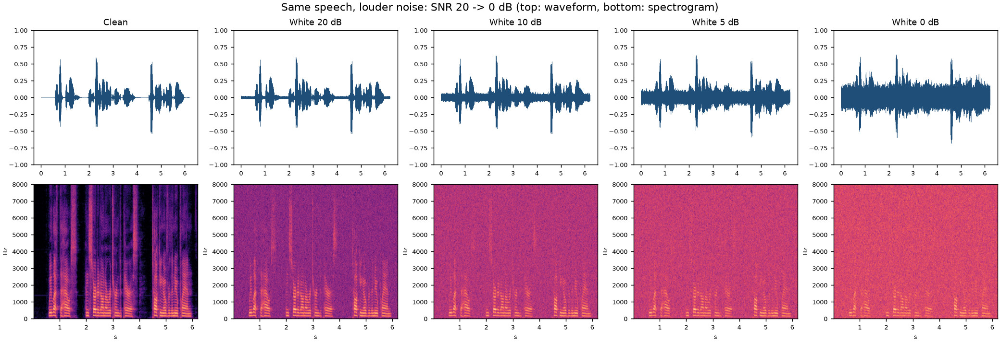

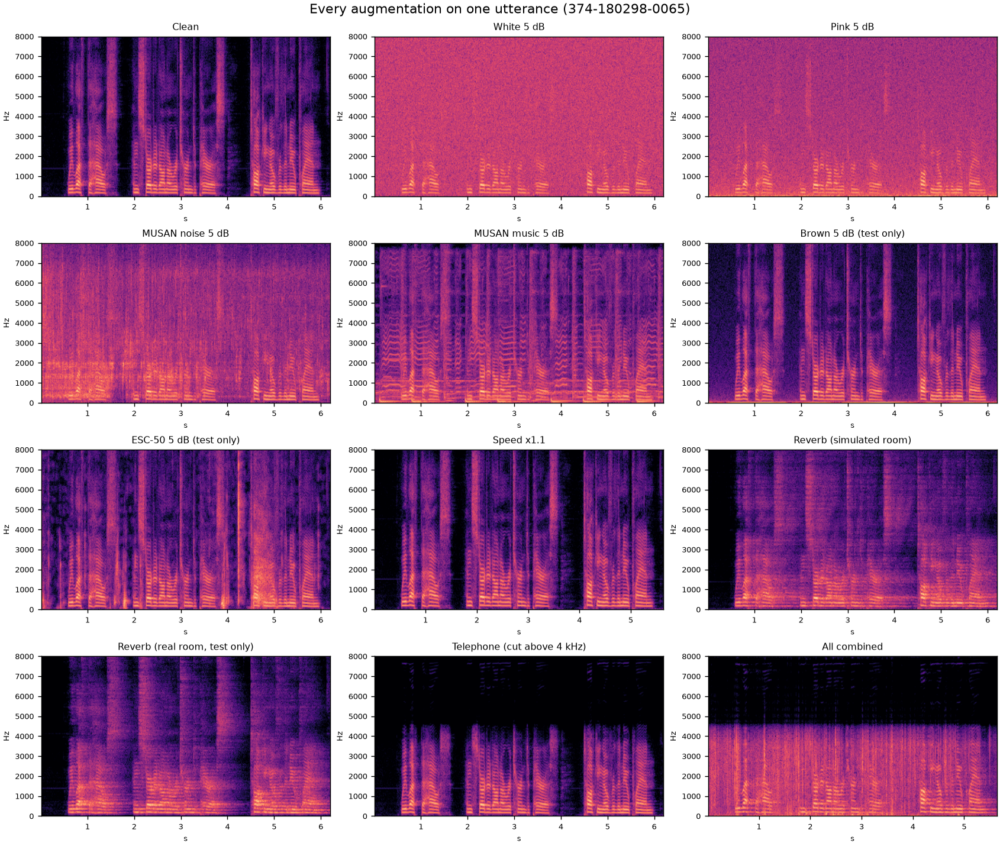

In [6]:
display(Image(filename=str(demo / "spectrograms_snr_levels.png"), width=1000))
display(Image(filename=str(demo / "spectrograms_all_augmentations.png"), width=1000))

## 3. Metrics

| Metric | Why it fits this problem |
|---|---|
| **WER** = (S + D + I) / N, pooled over all words | the words a user has to correct; comparable with published LibriSpeech results |
| **CER** | partial correctness, e.g. a name spelled almost right |
| S / D / I split | *how* noise breaks recognition |
| relative WER reduction, with **paired bootstrap 95 % CIs** | compares conditions of different difficulty, and shows whether a gain is larger than the noise |
| **breakdown SNR** | the SNR at which WER reaches 2 × the model's own clean WER (rule fixed before computing) |
| **AUROC**, precision-recall, F1 | does the detector rank wrong words first? (only 7.6 % of words are wrong, so accuracy is not used) |
| **errors caught vs share of words reviewed** | the product promise: check a small part, catch most errors |
| **ECE**, Brier, reliability diagram | the app shows the risk as a percentage, so it must be calibrated |
| replay-window hit rate | does "replay" play the audio that contains the error? (O4) |
| real-time factor | processing time ÷ audio duration, on CPU and GPU (O5) |

## 4. Quantitative results
### 4.1 Model comparison (the 22 Nov analysis, re-run here)

This step re-runs the analysis behind the 22 Nov report and regenerates its tables and figures.

,model,decoding,test-clean,test-other,noisy pooled,white 0-5 dB,pink 0-5 dB,brown 0-5 dB,esc50 0-5 dB
0,ref_base960h,greedy,3.43,8.59,29.99,80.68,65.55,6.55,34.67
1,A_clean,greedy,5.85,13.03,29.86,71.53,56.05,10.26,38.29
2,A_clean,4-gram LM,3.69,9.04,25.22,66.15,50.18,6.94,32.58
3,B_noisy,greedy,6.19,13.08,16.07,29.09,23.20,10.02,20.12
4,B_noisy,4-gram LM,3.70,8.85,11.62,22.79,17.63,6.55,15.09
5,B2_lr1e-4,greedy,5.89,13.11,15.85,28.56,22.81,9.99,19.56
6,B2_lr1e-4,4-gram LM,3.67,9.18,11.61,22.57,17.44,6.70,14.82
7,B460,greedy,4.70,11.09,13.36,24.84,19.44,8.22,16.66
8,B460,4-gram LM,2.97,7.58,9.85,19.60,15.01,5.56,12.66
9,B960_rev,greedy,4.63,9.95,12.38,23.39,18.18,7.49,15.39


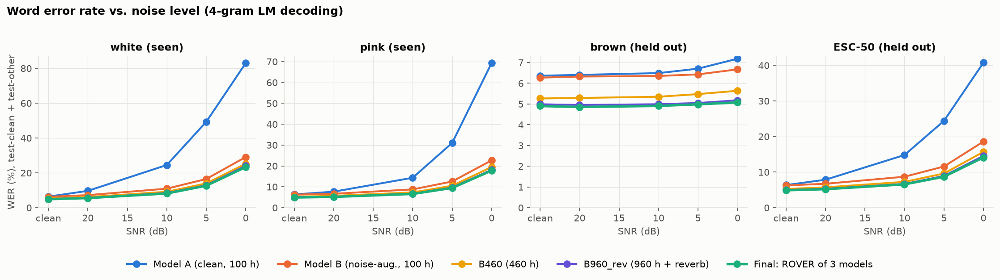

In [7]:
res = m5.core(ctx)
display(res["model_comparison"])
fig("m5_fig1_wer_vs_snr_all_models.png")

### 4.2 WER and CER in every condition (Objective O1)

The grids are pooled over test-clean and test-other.
The long table `g1_wer_cer_all_conditions.csv` also has each split separately, and the harder −5 dB and reverberation grid.

**WER (%)**

cond                            clean  white 20  white 10  white 5  white 0  pink 20  pink 10  pink 5  pink 0  brown 20  brown 10  brown 5  brown 0  esc50 20  esc50 10  esc50 5  esc50 0
decoding          system                                                                                                                                                                 
4-gram LM         A_clean        6.36      9.68     24.51    49.29    83.02     7.69    14.35   31.03   69.32      6.40      6.49     6.70     7.18      7.87     14.81    24.40    40.77
                  B2_lr1e-4      6.42      7.42     11.02    16.47    28.66     6.79     8.85   12.57   22.31      6.43      6.49     6.60     6.80      6.91      8.80    11.57    18.06
                  B460           5.27      6.12      9.15    13.95    25.24     5.68     7.33   10.51   19.50      5.29      5.35     5.48     5.64      5.73      7.26     9.62    15.69
                  B960_rev       4.99      5.65      8.42    12.91    24.04     5.25     6.70    9.66   18.17      4.95      4.99     5.05     5.18      5.32      6.69     8.93    14.57
                  B960_rev_s2    5.01      5.70      8.41    13.07    24.17     5.32     6.78    9.83   18.31      4.95      5.01     5.07     5.19      5.35      6.76     8.99    14.64
                  B_noisy        6.27      7.22     10.94    16.47    29.10     6.68     8.78   12.56   22.70      6.32      6.35     6.43     6.67      6.73      8.71    11.59    18.60
4-gram LM + ROVER rover3_final   4.90      5.53      8.17    12.62    23.31     5.19     6.60    9.47   17.80      4.86      4.91     4.98     5.08      5.21      6.56     8.70    14.14
greedy            A_clean        9.43     13.70     30.82    56.20    86.87    11.17    19.57   38.20   73.90      9.46      9.68    10.01    10.51     11.44     19.64    29.97    46.61
                  B2_lr1e-4      9.49     10.96     15.53    21.98    35.13    10.24    12.88   17.28   28.34      9.52      9.68     9.85    10.13     10.23     12.67    15.97    23.15
                  B460           7.89      9.00     12.83    18.55    31.14     8.46    10.55   14.34   24.54      7.91      7.95     8.09     8.35      8.41     10.39    13.27    20.04
                  B960_rev       7.28      8.23     11.74    17.35    29.42     7.74     9.66   13.35   23.00      7.25      7.30     7.40     7.58      7.83      9.49    12.21    18.56
                  B960_rev_s2    7.35      8.28     11.83    17.45    29.56     7.80     9.70   13.30   23.24      7.34      7.38     7.49     7.65      7.85      9.55    12.33    18.72
                  B_noisy        9.62     10.99     15.65    22.25    35.94    10.20    12.90   17.55   28.86      9.68      9.72     9.86    10.19     10.29     12.83    16.26    23.98
                  ref_base960h   6.00      9.79     34.08    68.18    93.19     7.44    18.78   47.17   83.93      6.01      6.13     6.37     6.72      7.56     15.20    26.44    42.91

**CER (%)**

cond                            clean  white 20  white 10  white 5  white 0  pink 20  pink 10  pink 5  pink 0  brown 20  brown 10  brown 5  brown 0  esc50 20  esc50 10  esc50 5  esc50 0
decoding          system                                                                                                                                                                 
4-gram LM         A_clean        2.51      4.39     14.06    33.04    66.51     3.24     7.27   18.91   52.99      2.51      2.57     2.67     2.94      3.36      7.76    14.47    27.78
                  B2_lr1e-4      2.55      3.15      5.30     8.76    17.00     2.80     4.00    6.27   12.57      2.57      2.60     2.66     2.78      2.84      3.98     5.69    10.12
                  B460           2.03      2.50      4.29     7.22    14.79     2.27     3.21    5.13   10.85      2.03      2.06     2.14     2.23      2.29      3.16     4.62     8.63
                  B960_rev       1.86      2.24      3.85     6.61    13.90     2.04     2.88    4.63    9.94      1.86      1.87     1.91     1.99      2.06      2.85     4.21     7.90
                  B960_rev_s2    1.88      2.28      3.87     6.69    14.05     2.07     2.92    4.69   10.05      1.87      1.89     1.93     1.99      2.09      2.88     4.25     7.96
                  B_noisy        2.49      3.04      5.27     8.84    17.47     2.72     3.97    6.29   12.89      2.50      2.53     2.57     2.70      2.75      3.96     5.74    10.56
4-gram LM + ROVER rover3_final   1.96      2.35      4.02     6.89    14.57     2.15     3.00    4.89   10.45      1.94      1.96     2.01     2.06      2.15      2.99     4.41     8.32
greedy            A_clean        3.16      5.20     14.68    31.17    58.60     3.97     8.23   18.96   48.16      3.18      3.29     3.42     3.64      4.13      8.59    14.95    27.12
                  B2_lr1e-4      3.22      3.92      6.20     9.69    17.50     3.54     4.86    7.16   13.31      3.23      3.29     3.36     3.49      3.56      4.76     6.51    10.69
                  B460           2.59      3.14      5.03     8.02    15.25     2.88     3.88    5.83   11.38      2.61      2.63     2.72     2.83      2.86      3.82     5.31     9.12
                  B960_rev       2.35      2.80      4.52     7.41    14.28     2.57     3.50    5.30   10.53      2.36      2.37     2.41     2.50      2.60      3.42     4.82     8.37
                  B960_rev_s2    2.38      2.84      4.56     7.43    14.32     2.60     3.53    5.31   10.61      2.37      2.40     2.44     2.54      2.62      3.46     4.86     8.40
                  B_noisy        3.20      3.90      6.20     9.79    17.86     3.49     4.84    7.20   13.55      3.23      3.26     3.34     3.45      3.54      4.81     6.59    11.08
                  ref_base960h   2.00      3.79     17.31    41.51    74.89     2.67     8.54   26.90   65.25      2.01      2.07     2.16     2.32      2.73      6.96    14.20    27.82

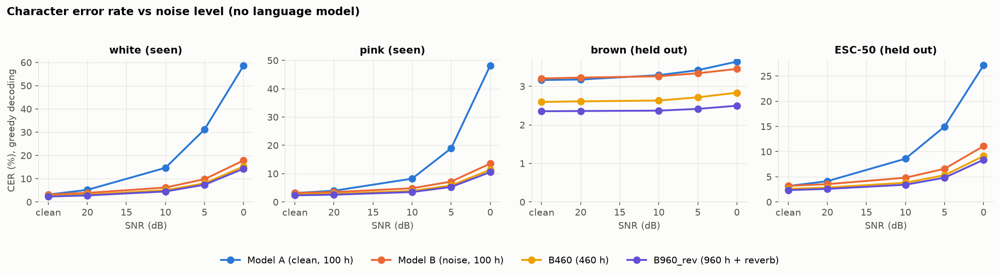

In [8]:
long = m5.g1_grid(ctx)
display(Markdown("**WER (%)**")); display(ctx.res["g1"]["wer"])
display(Markdown("**CER (%)**")); display(ctx.res["g1"]["cer"])
fig("g1_cer_vs_snr.png")

In [9]:
hard = long[long.decoding.str.startswith("greedy (harder") & (long.ls_split == "both")]
hard.pivot_table(index="system", columns=["noise_type", "snr"], values="wer_%").round(2)

noise_type   esc50   pink reverb+clean reverb+esc50                white
snr             -5     -5        clean            0      5     10     -5
system                                                                  
A_clean      61.65  98.11        21.82        65.97  52.09  41.37  99.26
B2_lr1e-4    36.85  53.86        20.30        46.73  35.92  29.82  59.25
B460         32.91  49.57        17.89        43.01  32.61  26.72  55.24
B960_rev     31.01  47.28        12.56        35.70  25.62  20.01  53.30
B960_rev_s2  31.28  47.25        12.57        35.75  25.65  20.04  53.01
B_noisy      38.21  55.32        20.18        47.51  36.36  29.93  60.73

### 4.3 Breakdown SNR per model and noise type

**Rule (fixed before computing):** the breakdown SNR is where WER first reaches **2 × the model's own clean WER**.
- It is interpolated linearly between the measured SNRs.
- An empty cell means the model never reaches that level, down to the lowest SNR tested.

A second view gives the SNR at which WER reaches 20 %.

In [10]:
b = m5.g2_breakdown(ctx)
col = [c for c in b.columns if c.startswith("breakdown")][0]
display(b.pivot_table(index=["decoding", "system"], columns="noise_type", values=col, sort=False))
b

noise_type                      white  pink  esc50
decoding          system                          
4-gram LM         A_clean        17.9  12.4   13.0
                  B2_lr1e-4       8.3   4.9    4.0
                  B460            8.6   5.0    4.3
                  B960_rev        8.3   4.8    4.1
                  B960_rev_s2     8.3   4.9    4.1
                  B_noisy         8.6   5.0    4.3
4-gram LM + ROVER rover3_final    8.2   4.8    4.0
greedy            A_clean        17.0  10.8   11.0
                  B2_lr1e-4       7.3   4.2    2.9
                  B460            7.4   4.3    3.1
                  B960_rev        7.5   4.4    3.1
                  B960_rev_s2     7.4   4.3    3.1
                  B_noisy         7.3   4.2    3.1
                  ref_base960h   19.1  16.0   14.2

,decoding,system,noise_type,clean_wer_%,lowest_snr_tested,wer_at_lowest_%,breakdown_snr_2x_clean,snr_wer_reaches_20%
0,4-gram LM,A_clean,white,6.36,0,83.02,17.9,13.0
1,4-gram LM,A_clean,pink,6.36,0,69.32,12.4,8.3
2,4-gram LM,A_clean,brown,6.36,0,7.18,NaN,NaN
3,4-gram LM,A_clean,esc50,6.36,0,40.77,13.0,7.3
4,4-gram LM,B2_lr1e-4,white,6.42,0,28.66,8.3,3.6
5,4-gram LM,B2_lr1e-4,pink,6.42,0,22.31,4.9,1.2
6,4-gram LM,B2_lr1e-4,brown,6.42,0,6.80,NaN,NaN
7,4-gram LM,B2_lr1e-4,esc50,6.42,0,18.06,4.0,NaN
8,4-gram LM,B460,white,5.27,0,25.24,8.6,2.3
9,4-gram LM,B460,pink,5.27,0,19.50,5.0,NaN


### 4.4 How accuracy rises and falls

Four views:
- **(a) during fine-tuning:** dev WER every 2,000 steps;
- **(b) change by change:** from Model A to the final system;
- **(c) with noise level:** word accuracy against SNR;
- **(d) across hyperparameters:** the M4 sweep.

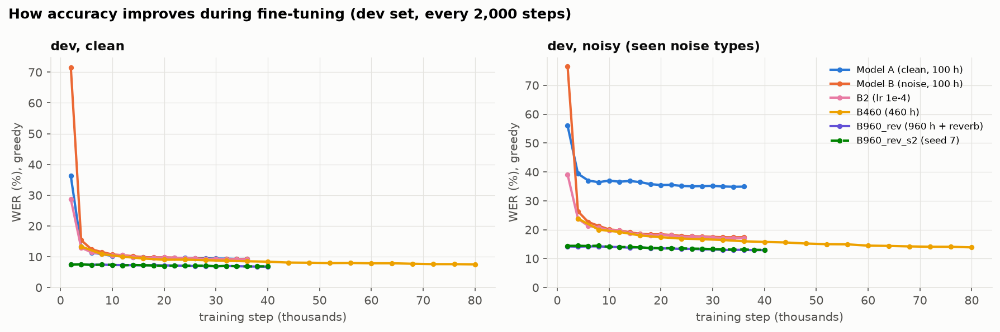

,step,wer_clean,wer_noisy,cer_clean,cer_noisy,model
16,34000,9.294,34.868,3.253,18.979,A_clean
53,36000,9.081,17.035,3.226,7.297,B2_lr1e-4
73,80000,7.520,13.900,2.614,5.887,B460
92,38000,6.810,12.932,2.268,5.402,B960_rev
113,40000,6.871,13.033,2.292,5.400,B960_rev_s2
34,34000,9.259,17.373,3.229,7.380,B_noisy


In [11]:
acc = m5.g3_accuracy(ctx)
fig("g3_training_curves.png")
display(acc["best_step"])

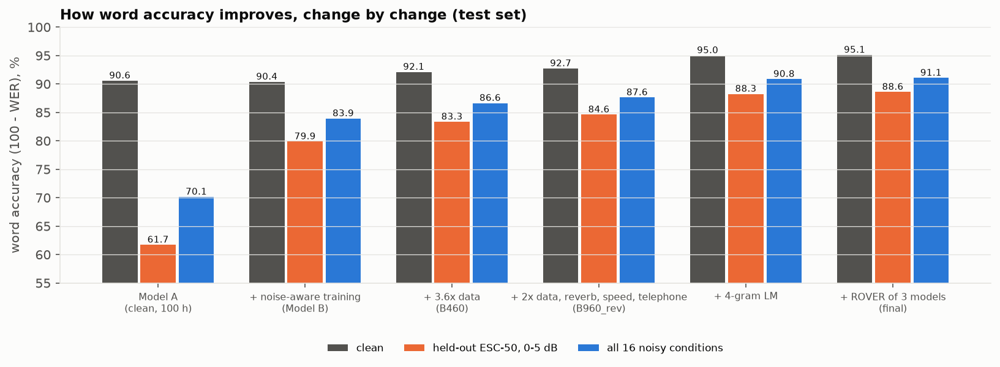

,step,change,system,decoding,wer_clean_%,wer_esc50_0-5dB_%,wer_all_noisy_%,acc_clean_%,rel_change_vs_prev_clean_%,acc_esc50_0-5dB_%,rel_change_vs_prev_esc50_0-5dB_%,acc_all_noisy_%,rel_change_vs_prev_all_noisy_%
0,"Model A (clean, 100 h)",start,A_clean,greedy,9.43,38.29,29.86,90.57,NaN,61.71,NaN,70.14,NaN
1,+ noise-aware training (Model B),noise training,B_noisy,greedy,9.62,20.12,16.07,90.38,2.1,79.88,-47.4,83.93,-46.2
2,+ 3.6x data (B460),more data,B460,greedy,7.89,16.66,13.36,92.11,-18.0,83.34,-17.2,86.64,-16.8
3,"+ 2x data, reverb, speed, telephone (B960_rev)",more data + augmentation,B960_rev,greedy,7.28,15.39,12.38,92.72,-7.7,84.61,-7.6,87.62,-7.3
4,+ 4-gram LM,language model,B960_rev,4-gram LM,4.99,11.75,9.16,95.01,-31.5,88.25,-23.7,90.84,-26.1
5,+ ROVER of 3 models (final),system combination,rover3_final,4-gram LM + ROVER,4.90,11.42,8.94,95.10,-1.7,88.58,-2.8,91.06,-2.3


In [12]:
fig("g3_accuracy_model_by_model.png")
acc["waterfall"]

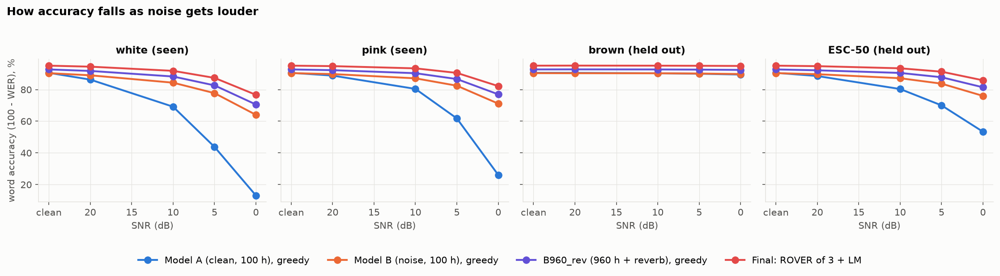

snr                         20     10     5      0 
system       noise_type                            
A_clean      white       86.30  69.18  43.80  13.13
             pink        88.83  80.43  61.80  26.10
             brown       90.54  90.32  89.99  89.49
             esc50       88.56  80.36  70.03  53.39
B_noisy      white       89.01  84.35  77.75  64.06
             pink        89.80  87.10  82.45  71.14
             brown       90.32  90.28  90.14  89.81
             esc50       89.71  87.17  83.74  76.02
B960_rev     white       91.77  88.26  82.65  70.58
             pink        92.26  90.34  86.65  77.00
             brown       92.75  92.70  92.60  92.42
             esc50       92.17  90.51  87.79  81.44
rover3_final white       94.47  91.83  87.38  76.69
             pink        94.81  93.40  90.53  82.20
             brown       95.14  95.09  95.02  94.92
             esc50       94.79  93.44  91.30  85.86

In [13]:
fig("g3_accuracy_vs_snr.png")
acc["acc_vs_snr"].pivot_table(index=["system", "noise_type"], columns="snr", values="accuracy_%", sort=False)

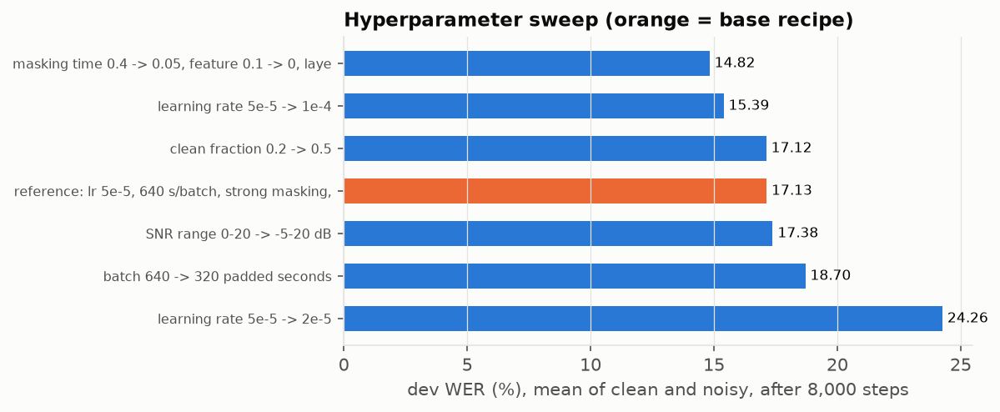

,run,change,dev_wer_avg_pct,delta_avg_vs_base_pts
3,hp_mask_light,"masking time 0.4 -> 0.05, feature 0.1 -> 0, layerdrop 0.1 -> 0.05",14.82,-2.3149
1,hp_lr1e-4,learning rate 5e-5 -> 1e-4,15.39,-1.7431
5,hp_pclean0.5,clean fraction 0.2 -> 0.5,17.12,-0.0120
0,hp_base,"reference: lr 5e-5, 640 s/batch, strong masking, p_clean 0.2, SNR 0-20 dB",17.13,0.0000
6,hp_snr-5,SNR range 0-20 -> -5-20 dB,17.38,0.2473
4,hp_bs320,batch 640 -> 320 padded seconds,18.70,1.5623
2,hp_lr2e-5,learning rate 5e-5 -> 2e-5,24.26,7.1227


In [14]:
fig("g3_hparam_sweep.png", 800)
acc["sweep"]

### 4.5 Are the differences real? Paired bootstrap 95 % confidence intervals

Settings:
- 1,000 resamples of the 5,559 test utterances (seed 0);
- all conditions of an utterance are resampled together, because they share the same speech;
- `diff_pts` = WER(Y) − WER(X) in percentage points, so a negative value means Y is better.

A difference is real when its CI excludes 0.

In [15]:
bt = m5.g4_bootstrap(ctx)
bt

,comparison,subset,wer_X_%,wer_Y_%,diff_pts,diff_ci_low,diff_ci_high,rel_change_%,rel_ci_low,rel_ci_high,share_boot_Y_better
0,noise training: A -> B (greedy),clean,9.428,9.625,0.196,0.072,0.307,2.082,0.782,3.270,0.000
1,noise training: A -> B (greedy),all noisy,29.858,16.072,-13.786,-13.965,-13.610,-46.173,-46.797,-45.574,1.000
2,noise training: A -> B (greedy),ESC-50 0-5 dB (held out),38.292,20.124,-18.168,-18.589,-17.733,-47.447,-48.155,-46.711,1.000
3,noise training: A -> B (greedy),brown 0-5 dB (held out),10.257,10.022,-0.235,-0.354,-0.133,-2.295,-3.413,-1.290,1.000
4,noise training: A -> B (greedy),white 0-5 dB,71.533,29.091,-42.441,-42.947,-41.959,-59.331,-59.961,-58.709,1.000
5,noise training: A -> B (4-gram LM),clean,6.362,6.269,-0.093,-0.200,0.008,-1.468,-3.108,0.123,0.965
6,noise training: A -> B (4-gram LM),all noisy,25.220,11.616,-13.604,-13.790,-13.424,-53.942,-54.700,-53.252,1.000
7,noise training: A -> B (4-gram LM),ESC-50 0-5 dB (held out),32.583,15.093,-17.490,-17.904,-17.033,-53.678,-54.472,-52.860,1.000
8,noise training: A -> B (4-gram LM),brown 0-5 dB (held out),6.943,6.548,-0.395,-0.492,-0.293,-5.683,-7.048,-4.224,1.000
9,noise training: A -> B (4-gram LM),white 0-5 dB,66.154,22.788,-43.366,-43.875,-42.882,-65.554,-66.235,-64.891,1.000


## 5. Visualisations of the error detector
### 5.1 ROC, precision-recall, confusion matrices, calibration

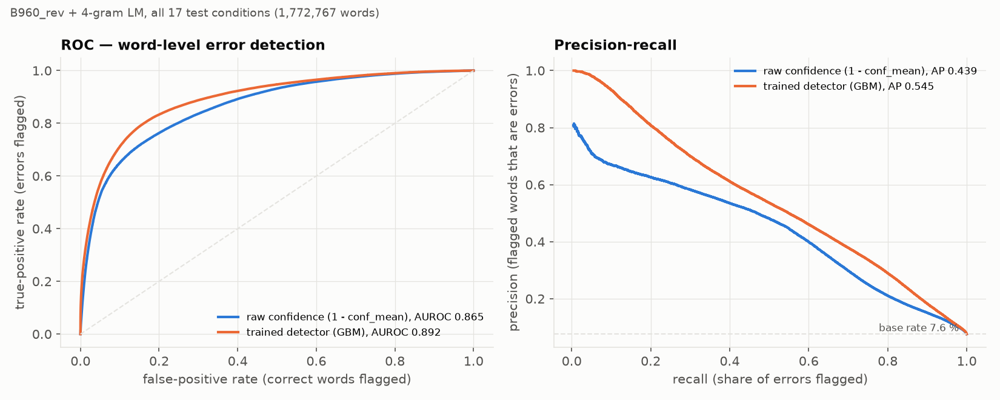

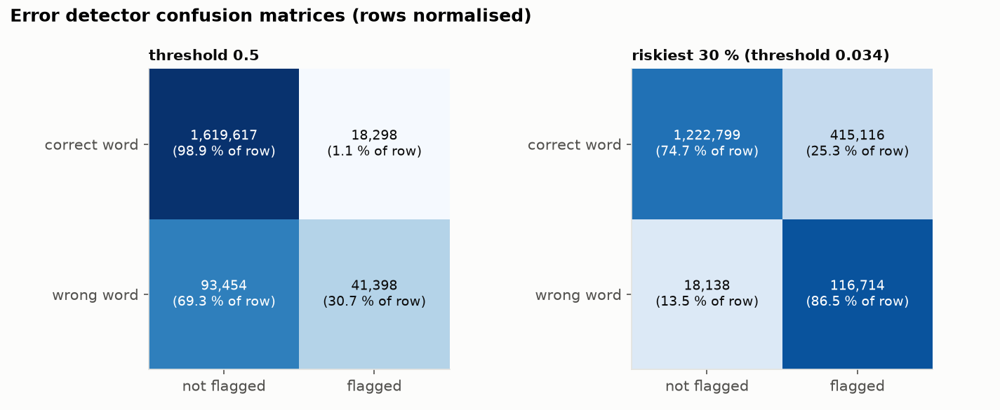

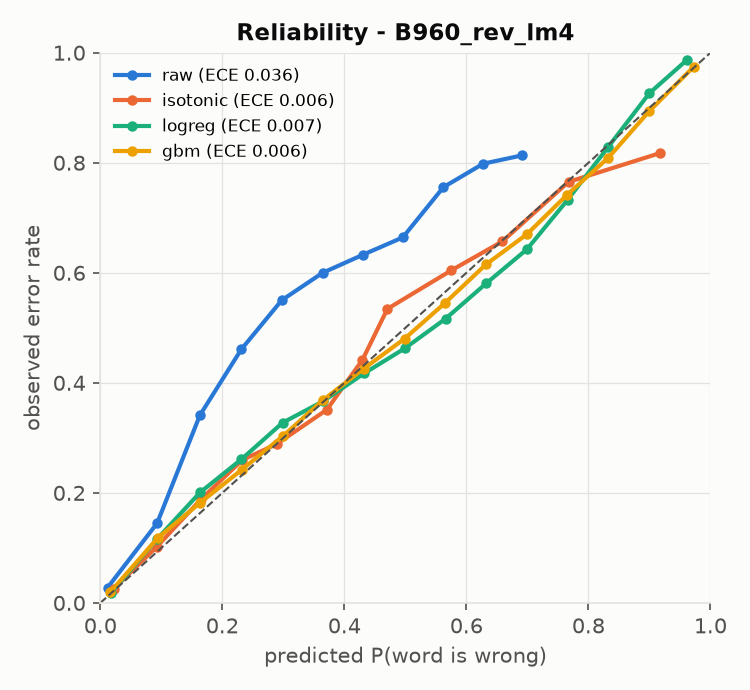

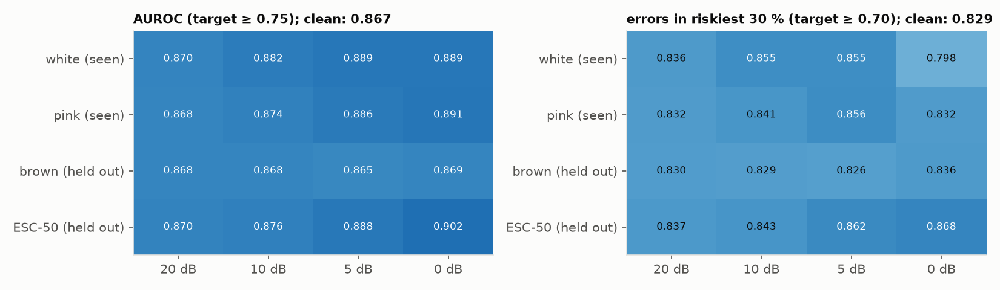

,operating_point,threshold,TN,FP,FN,TP,precision,recall,flagged_frac
0,threshold 0.5,0.5000,1619617,18298,93454,41398,0.6935,0.3070,0.0337
1,riskiest 30 % (threshold 0.034),0.0343,1222799,415116,18138,116714,0.2195,0.8655,0.3000


In [16]:
fig("m5_fig4_detector_roc_pr.png")
fig("m5_fig5_detector_confusion.png", 850)
display(Image(filename=str(REPO / "experiments/results/B960_rev_lm4/error_detector/reliability.png"), width=520))
fig("m5_fig7_detector_per_condition.png")
pd.read_csv(ctx.tab / "detector_confusion.csv")

### 5.2 Review effort: share of errors caught against share of words reviewed (Objective O3)

Milestone 1 promised this curve. It also promised two baselines that the detector must beat: **random flagging** and **raw confidence**.

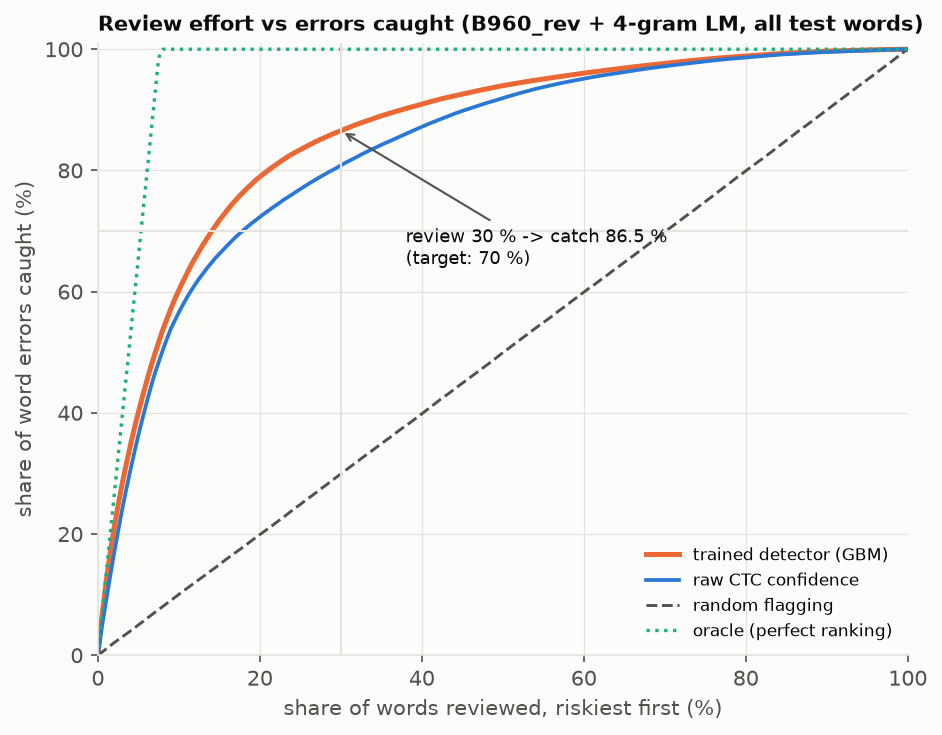

,subset,method,error_rate_%,errors_caught_reviewing_5%_%,errors_caught_reviewing_10%_%,errors_caught_reviewing_20%_%,errors_caught_reviewing_30%_%,errors_caught_reviewing_50%_%
0,all conditions,trained detector (GBM),7.61,40.12,60.26,78.96,86.55,93.98
1,all conditions,raw CTC confidence,7.61,36.36,56.61,72.35,80.84,91.93
2,all conditions,random flagging,7.61,4.99,10.06,19.92,29.91,49.93
3,all conditions,oracle (perfect ranking),7.61,65.73,100.00,100.00,100.00,100.00
4,clean,trained detector (GBM),4.53,43.61,60.57,75.60,82.85,91.82
5,clean,raw CTC confidence,4.53,37.12,50.71,65.28,74.95,89.53
6,clean,random flagging,4.53,5.21,10.19,20.03,30.58,50.13
7,clean,oracle (perfect ranking),4.53,100.00,100.00,100.00,100.00,100.00
8,noisy,trained detector (GBM),7.80,39.72,59.96,78.94,86.62,94.05
9,noisy,raw CTC confidence,7.80,35.94,56.53,72.48,80.96,92.01


,method,f1_at_0.5,best_f1,threshold_best_f1,precision_at_best,recall_at_best
0,trained detector (GBM),0.4256,0.5240,0.2466,0.4861,0.5682
1,raw CTC confidence,0.0679,0.4936,0.1268,0.4565,0.5372


In [17]:
rv = m5.g5_review(ctx)
fig("g5_review_effort_curve.png", 650)
display(rv["budgets"])
rv["f1"]

### 5.3 Other task-specific plots

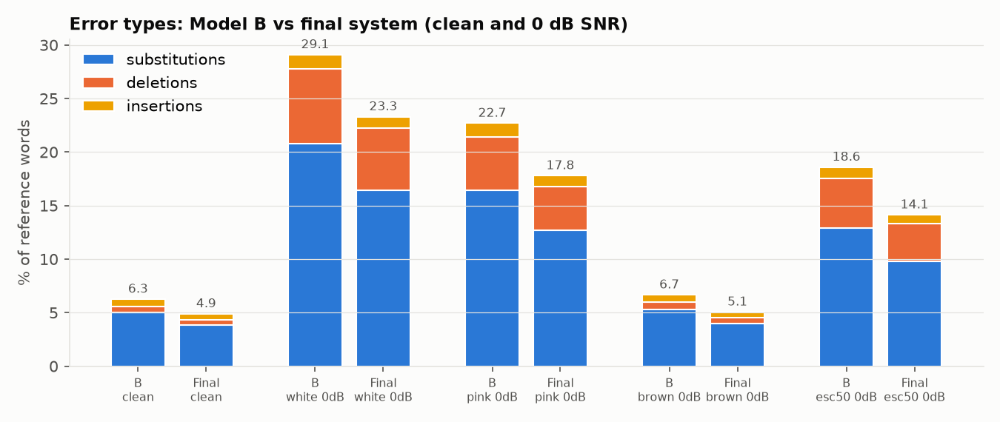

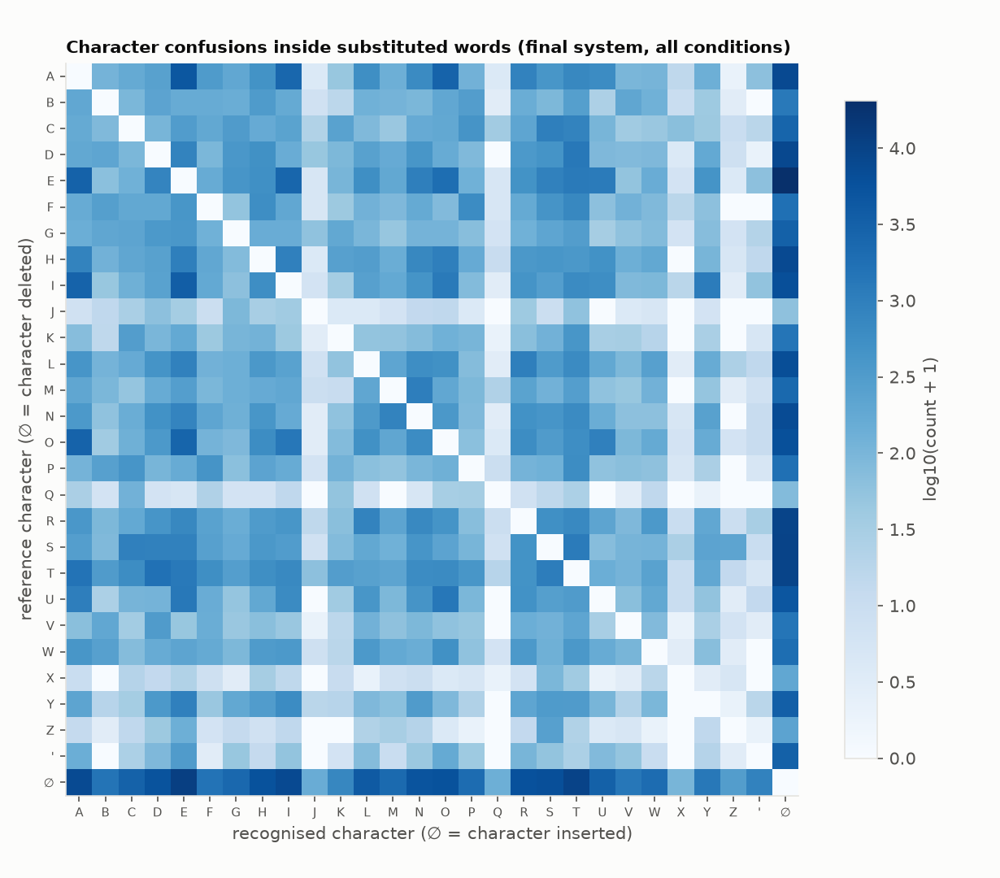

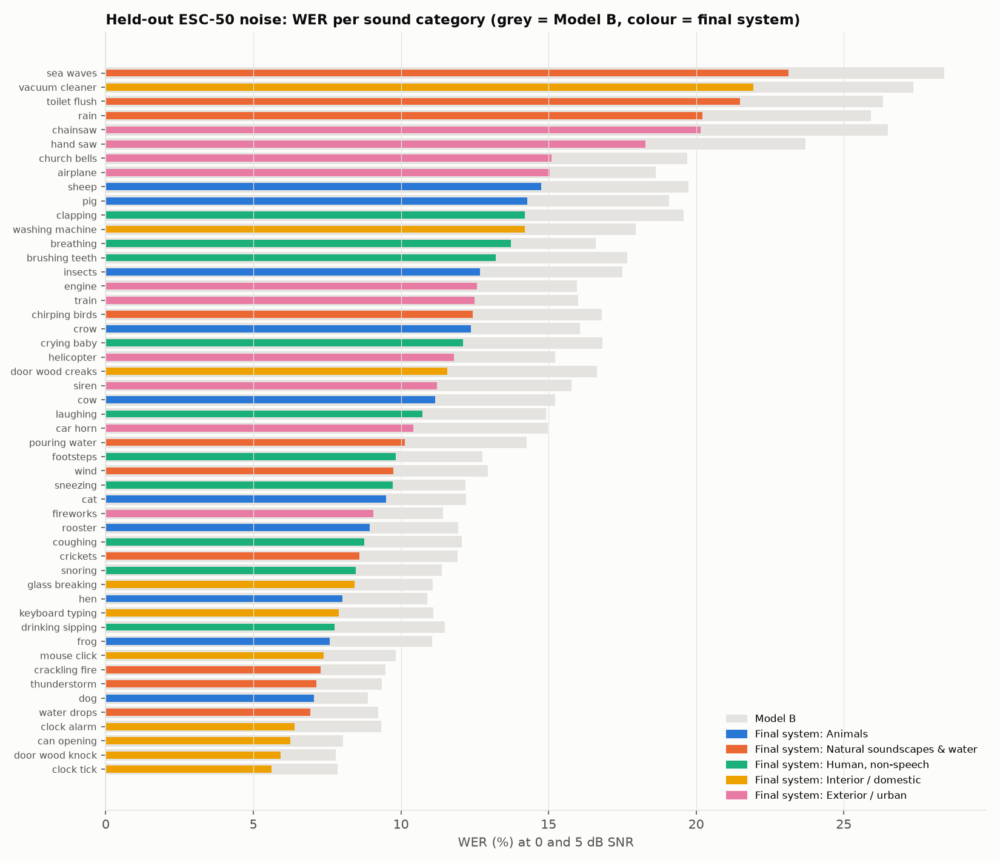

In [18]:
fig("m5_fig2_error_types.png", 850)
fig("m5_fig6_char_confusion.png", 650)
fig("m5_fig3_esc50_categories.png", 850)

## 6. Qualitative results: successes and failures, with the noisy audio

Each example is rebuilt **bit for bit** as the model heard it, using the same seeded noise clip, offset and gain as the test grid.

The examples are chosen systematically. For each noise type:
- the largest improvements over Model B;
- cases where the final system is worse than Model B;
- the hardest remaining utterances.

In [19]:
ex = m5.g8_audio(ctx)
for r in ex.itertuples():
    cond = r.noise_type + ("" if pd.isna(r.snr_db) else f" {int(r.snr_db)} dB")
    display(Markdown(f"**{r.kind}**, {cond}{', noise: ' + r.noise_clip if r.noise_clip else ''}  \n"
                     f"reference: `{r.reference}`  \nModel B ({r.errors_B} errors): `{r.model_B}`  \n"
                     f"final system ({r.errors_final} errors): `{r.final_system}`"))
    display(Audio(filename=str(OUT / r.file)))

**largest improvement over Model B**, clean  
reference: `SIX STEPPED TO THE FRONT SHERIFF GLISPIN COLONEL T L VOUGHT B M RICE G A BRADFORD C A POMEROY AND S J SEVERSON`  
Model B (11 errors): `SIX STEPS TO THE FRONT SHERFGLIFSPEN COLONEL TO VAULT B M RICE BRADFORD C POMEROY AND SEVERSON`  
final system (5 errors): `SIX STEPS TO THE FRONT SHERIFF GLISPIN COLONEL TO BOLT B M RICE G A BRADFORD C A POMEROY AND S J CEVERSON`

**largest improvement over Model B**, clean  
reference: `THUS SPAKE THE PEACEFUL ONE AND PUFFED HIMSELF AND PERSPIRED WITH HIS WORDS SO THAT THE KINE WONDERED ANEW`  
Model B (10 errors): `THUS BIG THE BREAST FULL WINE AND PUFFED HIMSELF AND BOYS PIED WITH HIS WORDS SO THAT THE KIND WINDED I KNEW`  
final system (5 errors): `THUS PIG THE BREITHFUL WARM AND PUFFED HIMSELF AND POSPIED WITH HIS WORDS SO THAT THE KIND WONDERED ANEW`

**final system worse than Model B**, clean  
reference: `PRESENTLY HASAN SHUMAN CAME OUT OF A CLOSET AND SAID TO HIM HAST THOU GOTTEN THE GEAR O ALI`  
Model B (2 errors): `PRESENTLY HASSAN SHUMAN CAME OUT OF A CLOSET AND SAID TO HIM HAST THOU GOTTEN THE YEAR O ALI`  
final system (6 errors): `PRESENTLY HASSAN SHUMAN CAME OUT OF A CLOSANAND SAID TO HIM HAST THOU GOT IN THE YEAR O ALI`

**hardest remaining (final system)**, clean  
reference: `O ETERNAL EVERYWHERE O ETERNAL NOWHERE O ETERNAL IN VAIN`  
Model B (15 errors): `I TURNED EVERY WHERE WHO I TURNED THERE IS NO WHERE WHO I TURNED TO IN VAIN`  
final system (12 errors): `I TURN THEM EVERY WHERE WHO TURN THERE IS NO OATEN O AUN IN VAIN`

**largest improvement over Model B**, white 0 dB, noise: white  
reference: `IT IS FAR BETTER TO BE FREE TO LEAVE THE FORTS AND BARRICADES OF FEAR TO STAND ERECT AND FACE THE FUTURE WITH A SMILE`  
Model B (19 errors): `IF I SAW THAT IT OBESE WHO MADE THE FORD AND VERY COOPER WHO STAND ERECT AND FACE WAS PEACEFUL DIE`  
final system (7 errors): `IT IS FAR BETTER TO BE FREE TO LEAVE THE FORD AND VERY HARD OF FEAR TO STAND ERECT AND FACE THE DIS`

**largest improvement over Model B**, white 0 dB, noise: white  
reference: `I REALLY WAS VERY MUCH AFRAID OF SHOWING HIM HOW MUCH SHOCKED I WAS AT SOME PARTS OF WHAT HE SAID`  
Model B (15 errors): `ARE TENUEFRAID OF SHOWING THEM HOW MUCH SHELFORWAS OF SOME PART OF WAPENTAKE`  
final system (5 errors): `I REALLY FEEL VERY MUCH AFRAID OF SHOWING THEM HOW MUCH SHOP I WAS OF SOME PART OF WHAT HE SAID`

... (10 outputs left out)

**largest improvement over Model B**, esc50 0 dB, noise: 4-149294-B-41.wav  
reference: `ALL SORTS OF INFERIOR PEOPLE LIVED THERE AND SO BRILLIANT A WOMAN AS MISSUS FARRINDER WHO LIVED AT ROXBURY OUGHT NOT TO MIX THINGS UP`  
Model B (21 errors): `IT SUSIANIANSOD BRILLIANT MISSUS SPAIN DO WE LIVE A FRORE NOT NOT TO MIX TENSE`  
final system (10 errors): `I SORT OF ILIOPEOPLEBI THERE AND SO BRILLIANT A WOMAN AS MISSUS PARMINTER WHO LIVED AT RAPTURE MUCH NOT TO MIX THESE`

**largest improvement over Model B**, esc50 0 dB, noise: 3-119459-A-26.wav  
reference: `THUS SPAKE THE PEACEFUL ONE AND PUFFED HIMSELF AND PERSPIRED WITH HIS WORDS SO THAT THE KINE WONDERED ANEW`  
Model B (15 errors): `DOES BIG THEBES FULL ROABOFFTHIMSELF AND ASPIRED WITH HIS CORDS ATTENDED BONDED ANEW`  
final system (6 errors): `THUS PAGE THE PEACEFUL WOOD AND PUFFED HIMSELF AND CLOSE BY WITH HIS WORDS WAS THAT THE KIND WONDERED ANEW`

**final system worse than Model B**, esc50 0 dB, noise: 1-23706-A-49.wav  
reference: `ALREADY A NORTH AND A SOUTH WERE TALKED OF WHY NOT SET UP ALSO A WEST`  
Model B (2 errors): `ALREADY A NORTH AND THE SOUTH WERE TALKED OF ONE NOT SET UP ALSO A WEST`  
final system (8 errors): `ALREADY A NORTH AND SOUTH OR UP ALSO AT WEST`

**hardest remaining (final system)**, esc50 0 dB, noise: 2-78781-A-47.wav  
reference: `THE SHUTTERS WERE CLOSED AND THIS CAUSED BUNKER AN INSTANT'S DELAY THAT WAS ALMOST FATAL PITTS CHASED HIM WITH A BULLET`  
Model B (19 errors): `THE SHOUT OF HER COSTUMES CAVENDER INSTANT ALIVE BUT WAS MISTAKEN HIS CHASTITY`  
final system (19 errors): `THE SHOW OF HER COAMISCARBUNKER MISS MISS CARBUNTER AND INSTANT TOILET WAS A MISTAKE HIS CHASTENING`

## 7. Error analysis

Five views:
- error types;
- word frequency and length;
- utterance duration and speakers;
- the most frequent confusions;
- which errors the flags catch.

In [20]:
display(Markdown("**Error types (final system)**"))
display(pd.read_csv(ctx.tab / "error_types_SDI.csv").query("system == 'rover3_final'"))
display(Markdown("**Word error by word frequency and by word length**"))
display(pd.read_csv(ctx.tab / "error_by_word_frequency.csv")); display(pd.read_csv(ctx.tab / "error_by_word_length.csv"))
display(Markdown("**By utterance duration / per speaker (clean)**"))
display(pd.read_csv(ctx.tab / "error_by_duration.csv")); display(pd.read_csv(ctx.tab / "per_speaker_wer_clean.csv"))
display(Markdown("**Most frequent word substitutions**"))
display(pd.read_csv(ctx.tab / "top_word_substitutions.csv").head(15))
display(Markdown("**Words the LM fixes vs breaks**"))
display(pd.read_csv(ctx.tab / "lm_fixed_vs_broken_words.csv").head(10))
display(Markdown("**ESC-50 sound classes**"))
display(pd.read_csv(ctx.tab / "esc50_per_group.csv"))
print(json.dumps(json.load(open(ctx.tab / "summary.json"))["oov"], indent=1))

**Error types (final system)**

,system,noise_type,snr,N_ref_words,sub_%,del_%,ins_%,wer_%
34,rover3_final,brown,0,104919,3.97,0.55,0.55,5.08
35,rover3_final,brown,5,104919,3.90,0.55,0.54,4.98
36,rover3_final,brown,10,104919,3.82,0.54,0.54,4.91
37,rover3_final,brown,20,104919,3.80,0.51,0.54,4.86
38,rover3_final,clean,clean,104919,3.84,0.52,0.54,4.90
39,rover3_final,esc50,0,104919,9.77,3.55,0.82,14.14
40,rover3_final,esc50,5,104919,6.53,1.49,0.69,8.70
41,rover3_final,esc50,10,104919,5.09,0.86,0.61,6.56
42,rover3_final,esc50,20,104919,4.08,0.58,0.56,5.21
43,rover3_final,pink,0,104919,12.67,4.11,1.02,17.80


**Word error by word frequency and by word length**

,freq_bin,noisy,size,word_error_%
0,rare (< -6),False,1071,66.67
1,rare (< -6),True,17136,73.51
2,-6 to -5,False,3688,24.67
3,-6 to -5,True,59008,32.68
4,-5 to -4,False,21211,6.15
5,-5 to -4,True,339376,11.72
6,-4 to -3,False,34623,2.43
7,-4 to -3,True,553968,5.99
8,frequent (> -3),False,44326,1.81
9,frequent (> -3),True,709216,4.78


,len_bin,noisy,size,word_error_%
0,1-2,False,21841,2.54
1,1-2,True,349456,5.90
2,3-4,False,44280,2.87
3,3-4,True,708480,6.38
4,5-6,False,20717,6.15
5,5-6,True,331472,10.80
6,7-8,False,11471,7.60
7,7-8,True,183536,12.46
8,9+,False,6610,9.11
9,9+,True,105760,13.43


**By utterance duration / per speaker (clean)**

... (5 outputs left out)

,fixed_word,fixed_n,broken_word,broken_n
0,AND,1958,THE,350
1,THE,1791,AND,305
2,A,1396,TO,285
3,IN,911,IN,280
4,TO,784,OF,275
5,OF,655,A,267
6,IT,473,IT,180
7,I,439,IS,174
8,YOU,422,THIS,115
9,THAT,349,AN,110


**ESC-50 sound classes**

,group,wer_B_noisy_lm4,wer_rover3_final
0,Animals,14.26,10.63
1,Exterior / urban,17.79,13.61
2,"Human, non-speech",14.54,10.85
3,Interior / domestic,12.69,9.56
4,Natural soundscapes & water,16.46,12.70


{
 "ref_words": 1783623,
 "oov_in_lm_frac": 0.004794174553703333,
 "oov_word_error_%": 87.94293065138581
}


### 7.1 Which wrong words get flagged? (numbers, names, rare words, function words)

**Substitutions:** an error counts as caught when the wrong word in its place is flagged.

**Deletions:** an error counts as caught when one of the two neighbouring words is flagged, because that word's replay covers the gap.

Word categories are taken from the reference word.

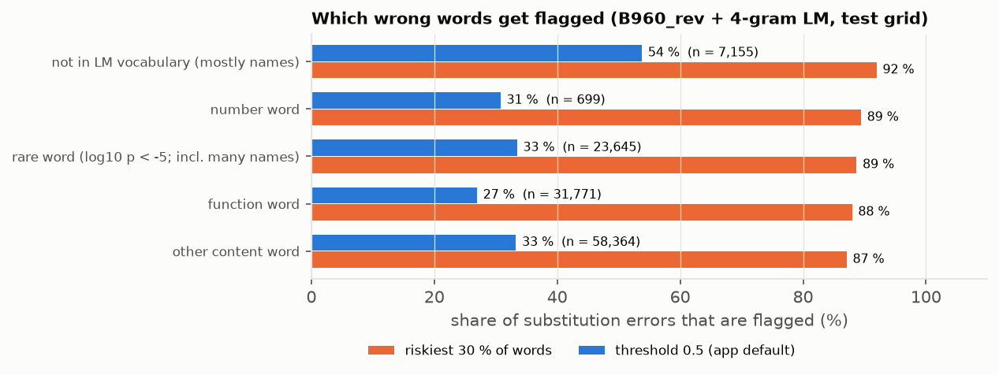

,error_type,category,n_errors,caught_at_0_5,caught_in_riskiest_30,share_of_errors_%
0,deletion,function word,10635,61.29,94.24,44.18
1,deletion,not in LM vocabulary (mostly names),400,93.50,100.00,1.66
2,deletion,number word,200,73.50,99.50,0.83
3,deletion,other content word,10476,73.02,96.30,43.52
4,deletion,rare word (log10 p < -5; incl. many names),2363,77.95,98.77,9.82
5,substitution,function word,31771,26.94,87.96,26.12
6,substitution,not in LM vocabulary (mostly names),7155,53.77,91.95,5.88
7,substitution,number word,699,30.76,89.41,0.57
8,substitution,other content word,58364,33.27,87.08,47.98
9,substitution,rare word (log10 p < -5; incl. many names),23645,33.44,88.69,19.44


In [21]:
ct = m5.g6_catch(ctx)
fig("g6_flags_by_error_category.png", 850)
ct

## 8. Product objectives
### 8.1 Replay window (O4) and the listening sheet

This is the automatic check of all 59,696 flags, plus the 50 randomly sampled flags exported as audio.

**For the team:** play each clip and fill in `heard_target_word` in
`milestones/M5_evaluation/replay_check/sample_flags.csv` (yes / no).

In [22]:
ls = m5.g9_listen(ctx)
display(pd.DataFrame(ctx.res["g9"]["summary"]["by_threshold"]).T)
for r in ls.head(50).itertuples():
    display(Markdown(f"**{r.clip}** · {r.condition} · flagged **{r.flagged_word}** (risk {r.p_error:.2f}) · "
                     f"target **{r.target_word}** at {r.target_start_s:.2f}–{r.target_end_s:.2f} s · window {r.window_start_s:.2f}–{r.window_end_s:.2f} s"))
    display(Audio(filename=str(REPO / r.clip_path)))

,n_flags,hit_rate,hit_rate_true_errors,precision
0.3,132608.0,0.993326,0.987908,0.524471
0.5,59696.0,0.990318,0.986569,0.693480
0.7,27701.0,0.987834,0.985746,0.840836


**flag_01.flac** · white 10 dB · flagged **WEDGED** (risk 0.64) · target **WITH** at 11.08–11.24 s · window 10.08–12.68 s

**flag_02.flac** · white 0 dB · flagged **THE** (risk 0.50) · target **IN** at 4.16–4.22 s · window 3.12–5.18 s

**flag_03.flac** · white 20 dB · flagged **SAPUCACID** (risk 0.99) · target **SULPHURIC** at 3.10–3.54 s · window 2.08–4.98 s

**flag_04.flac** · clean · flagged **FORCHEVIL** (risk 0.98) · target **FAUCHELEVENT** at 0.96–1.60 s · window 0.00–2.56 s

**flag_05.flac** · esc50 5 dB · flagged **DEARY** (risk 0.81) · target **DEW** at 11.76–11.94 s · window 10.76–12.62 s

... (41 outputs left out)

**flag_47.flac** · brown 20 dB · flagged **FOLLOW** (risk 0.78) · target **FOLLOWED** at 0.68–1.02 s · window 0.00–1.98 s

**flag_48.flac** · white 10 dB · flagged **CINOPORTINGMIS** (risk 0.99) · target **KIND** at 2.32–2.62 s · window 1.32–4.28 s

**flag_49.flac** · clean · flagged **DARLOT** (risk 0.96) · target **DEDALOS** at 1.38–1.88 s · window 0.38–2.21 s

**flag_50.flac** · pink 0 dB · flagged **CONTINENT** (risk 0.60) · target **CONFUSION** at 9.50–9.98 s · window 8.48–11.04 s

### 8.2 Speed: CPU (4 threads) and GPU (O5)

The test material is six recordings of about 2 minutes, each clean, with ESC-50 at 5 dB and with white noise at 5 dB.
The pipeline is the one the app uses: model + pruned 3-gram LM + detector.

Timings change slightly from run to run, so this table is not part of the identical-results check.

In [23]:
if RUN_GPU:
    sp = m5.g7_speed(ctx)
else:
    sp = pd.read_csv(ctx.tab / "g7_speed_summary.csv")
sp

Loading weights:   0%|          | 0/213 [00:00<?, ?it/s]

Loading the LM will be faster if you build a binary file.
Reading /home/user1/DSAI/Group-9-DS-and-AI-Lab-Project/data/raw/librispeech_lm/3-gram.pruned.1e-7.arpa
----5---10---15---20---25---30---35---40---45---50---55---60---65---70---75---80---85---90---95--100
****************************************************************************************************


Loading weights:   0%|          | 0/213 [00:00<?, ?it/s]

Loading the LM will be faster if you build a binary file.
Reading /home/user1/DSAI/Group-9-DS-and-AI-Lab-Project/data/raw/librispeech_lm/3-gram.pruned.1e-7.arpa
----5---10---15---20---25---30---35---40---45---50---55---60---65---70---75---80---85---90---95--100
****************************************************************************************************


,device,condition,rtf_mean,rtf_max,seconds_per_2_min,acoustic_share,wer_mean_pct
0,"CPU, 4 threads",clean,0.0498,0.0501,5.978,0.9320,10.5910
1,"CPU, 4 threads",esc50 5 dB,0.0502,0.0510,6.024,0.9320,12.4183
2,"CPU, 4 threads",white 5 dB,0.0506,0.0512,6.074,0.9320,16.7925
3,GPU (NVIDIA L40S),clean,0.0049,0.0051,0.588,0.3593,10.5910
4,GPU (NVIDIA L40S),esc50 5 dB,0.0053,0.0059,0.636,0.3593,12.5079
5,GPU (NVIDIA L40S),white 5 dB,0.0057,0.0062,0.684,0.3593,17.0869


## 9. Reproducibility: server models vs Hugging Face (O6)

This section runs two checks:
1. **Same weights:** each model's weights on the server are compared with its Hugging Face copy. The hash covers tensor values only, so file metadata doesn't matter.
2. **Same outputs:** the Hugging Face copy of B960_rev re-decodes the **full test grid** (94,503 utterances) on the GPU, and its hypotheses are compared word for word with the saved results.

In [24]:
if RUN_GPU:
    rp = m5.g12_repro(ctx)
    display(rp["weights"][["model", "hf_id", "identical_weights"]]); display(rp["decode"])
else:
    display(pd.read_csv(ctx.tab / "g12_weights_local_vs_hf.csv")); display(pd.read_csv(ctx.tab / "g12_hf_redecode_vs_saved.csv"))

,model,hf_id,identical_weights
0,A_clean,kumargulshan/wav2vec2-base-ls100-clean,True
1,B_noisy,kumargulshan/wav2vec2-base-ls100-noise-aug,True
2,B2_lr1e-4,kumargulshan/wav2vec2-base-ls100-noise-aug-lr1e-4,True
3,B460,kumargulshan/wav2vec2-base-ls460-noise-aug,True
4,B960_rev,kumargulshan/wav2vec2-base-ls960-noise-robust,True
5,B960_rev_s2,kumargulshan/wav2vec2-base-ls960-noise-robust-seed7,True


,model,hf_id,utterances,identical_hypotheses,identical_%,max_abs_wer_diff_per_condition
0,B960_rev,kumargulshan/wav2vec2-base-ls960-noise-robust,94503,94503,100.0,0.0


## 10. Objectives (Milestone 1) — target, result, evidence

In [25]:
ob = m5.g11_objectives(ctx)
ob

,objective,name,target,result,evidence,status
0,O1,Characterise ASR degradation under noise,complete WER/CER grid + WER-vs-SNR plot; breakdown SNR per model,"WER+CER for 8 systems x 17 conditions (+ -5 dB, reverb); breakdown SNR (WER = 2 x clean), Model A vs B960_rev: white...","g1, g2, Fig. 1, report 3.7",met
1,O2,Benefit of noise-aware training,>= 15 % relative WER cut at 0-5 dB (held-out noise); clean <= +2 pts,ESC-50 0-5 dB: -47.4 % (95 % CI -48.2 to -46.7); clean +0.20 pts (CI +0.07 to +0.31),"g4, report 3.5",met
2,O3,Detect error-prone words,AUROC >= 0.75; >= 70 % of errors in riskiest 30 %; ECE <= 0.10,"AUROC 0.892, recall@30 % 86.5 %, ECE 0.006","g5, Figs. 2-6",met
3,O4,Link flags to the right audio,>= 90 % of 50 sampled flags inside +-1 s,"99.0 % of 59,696 flags (automatic); 50-clip listening sheet in g9","g9, report 3.4",met (automatic); listening check by the team
4,O5,Working MVP,"upload, chunking, transcription, flags, replay, edit, export; RTF <= 1.0 on CPU (<= 2 min)",worst CPU RTF 0.051,"g7, app",met
5,O6,Reproducibility,a teammate reproduces the results from the README,weights identical local vs HF: 6/6; full-grid re-decode from HF: B960_rev 100.00 % identical,"g12, this notebook",evidence in place; teammate re-run to confirm


## 11. Observations and limitations

The full discussion is in the report, `milestones/M5_evaluation/Milestone5_Group9_Evaluation_Report.md`. In short:

- **Noise-aware training generalises to unseen noise.** ESC-50 at 0–5 dB improves by about half from Model A to Model B, with a tight CI. All 50 sound classes improve further with more data.
- **Data matters more than tuning.** The learning rate changes the final WER by less than 0.6 points, while 100 h → 960 h cuts it by a fifth or more.
- **The language model is the largest cheap gain.** It is also the main source of fluent wrong words.
- **The flags beat both baselines** at every review budget. Reviewing 30 % of words catches about 87 % of errors.
  - Names and out-of-vocabulary words are flagged most often.
  - Fluent function-word swaps are flagged least often.
- **Limits:**
  - read speech only, with synthetic noise mixing;
  - the full-band SNR makes brown noise look harmless;
  - a deleted word has no word of its own to flag.